In [1]:
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, roc_auc_score, accuracy_score
from sklearn.preprocessing import MinMaxScaler
import itertools
import utility, importlib; importlib.reload(utility)
random.seed(42)
np.random.seed(42)

In [2]:
names = pd.read_excel('../preprocessed_data/feature_names.xlsx')
keys = names['keys'].dropna().tolist()
label_names = names['label_names'].dropna().tolist()
demographic_cols = names['demographic_cols'].dropna().tolist()
proteomic_cols = names['proteomics_cols'].dropna().tolist()
metabolomics_cols = names['metabolomics_cols'].dropna().tolist()
neuropsychological_cols = names['neuropsychological_cols'].dropna().tolist()

In [3]:
df_omics_full = pd.read_csv('../preprocessed_data/omics_aibl_demo_imputed.csv')
print(df_omics_full.shape)
df_omics_full_clean = utility.prep_omics(df_omics_full)
print(df_omics_full_clean.shape)
df_omics_full_clean = utility.prepare_normalised_dataset(
    df=df_omics_full_clean,
    omics_features=proteomic_cols + metabolomics_cols,
    numeric_demographic_cols=['Demographic.Years of Education Exact', 'Age','Vital Signs.Body Mass Index', 'Demographic.GDS'],
    discrete_demo = ['APOE4', 'Demographic.Sex',
       'Demographic.Primary Occupation', 'Demographic.Retirement Status',
       'Demographic.Current Marital Status', 'Demographic.Country of Birth']+ neuropsychological_cols,
    keys=keys,
    label_names=label_names
)

(90, 1965)
(90, 1965)


In [4]:
# demographic_cols = [c for c in demographic_cols if c != "Demographic.Handedness"] + [
#     "Demographic.Handedness_Left",
#     "Demographic.Handedness_Right",
#     "Demographic.Handedness_Ambidextrous"
# ]
demographic_cols_used = ['Demographic.Years of Education Exact', 'Age',
                         'Vital Signs.Body Mass Index', 
                         'APOE4', 'Demographic.Sex',"Demographic.Handedness_Left",
                         "Demographic.Handedness_Right","Demographic.Handedness_Ambidextrous"]
# metabolomics_cols = [c.replace(":", ".") for c in metabolomics_cols]

## Models

1) baseline feature: age gender edu APOE4
2) proteomic
3) metabolomics
4) full

In [5]:
# keys 
# label_names 
# demographic_cols 
# proteomic_cols 
# metabolomics_cols 
# neuropsychological_cols 
# demographic_cols + proteomic_cols + metabolomics_cols + neuropsychological_cols

### 1) baseline feature

In [6]:
baseline_fts = ['Demographic.Years of Education Exact','Age','APOE4','Demographic.Sex']
model_baseline_df, model_baseline_df_M, model_baseline_df_F = utility.split_dataset_by_sex(df_omics_full_clean, baseline_fts + ['label'], sex_col='Demographic.Sex')

In [7]:
lr_param_grid_bl = {
    'C': [1],  
    'penalty': [None],  
    'solver': ['saga']  
}
lr_param_combinations_bl = list(itertools.product(lr_param_grid_bl['C'], lr_param_grid_bl['penalty'], lr_param_grid_bl['solver']))

In [8]:
# overall evaluation - baseline model
(results_lr_baseline, 
 overall_auc_lr_baseline, 
 median_auc_lr_baseline, 
 iqr_auc_lr_baseline, 
 iqr13_auc_lr_baseline,
 metrics_summary_lr_baseline) = utility.run_multiple_evaluations_parallel(
    model_baseline_df, 
    'logistic_regression', 
    lr_param_combinations_bl, 
    n_runs=10, 
    global_seed=42
)

results_lr_baseline_auc_scores_fold = utility.extract_results(results_lr_baseline, 'auc_scores_fold')
fold_metrics_lr_baseline = utility.extract_results(results_lr_baseline, 'fold_metrics')

# Create evaluation DataFrame for boxplot
eval_df_baseline_combined = pd.DataFrame({
    'Model': ['LR (Baseline)'] * len(results_lr_baseline_auc_scores_fold),
    'Groups': ['Full Cohort'] * len(results_lr_baseline_auc_scores_fold),
    'Features': ['Basic'] * len(results_lr_baseline_auc_scores_fold),
    'AUC': results_lr_baseline_auc_scores_fold,
    'Accuracy': [m['accuracy'] for m in fold_metrics_lr_baseline],
    'Sensitivity': [m['sensitivity'] for m in fold_metrics_lr_baseline],
    'Specificity': [m['specificity'] for m in fold_metrics_lr_baseline]
})

# Extract predictions (for ROC curve)
y_true_list_lr_baseline = utility.extract_results(results_lr_baseline, 'y_true')
y_pred_prob_list_lr_baseline = utility.extract_results(results_lr_baseline, 'y_pred_prob')
y_pred_list_lr_baseline = utility.extract_results(results_lr_baseline, 'y_pred')

# Extract features
feature_selection_df_lr_baseline = utility.extract_results(results_lr_baseline, 'feature_selection_df')
feature_sum_coef_df_lr_baseline = utility.extract_results(results_lr_baseline, 'feature_coef_df')

# Print results (now includes all metrics from metrics_summary)
print(f"Overall AUC: {overall_auc_lr_baseline:.4f}, Median AUC: {median_auc_lr_baseline:.4f}, IQR: {iqr_auc_lr_baseline:.4f}, IQ1-IQ3: {iqr13_auc_lr_baseline}")
print(f"Median Accuracy: {metrics_summary_lr_baseline['accuracy']['median']:.4f} [{metrics_summary_lr_baseline['accuracy']['q1']:.4f}, {metrics_summary_lr_baseline['accuracy']['q3']:.4f}]")
print(f"Median Sensitivity: {metrics_summary_lr_baseline['sensitivity']['median']:.4f} [{metrics_summary_lr_baseline['sensitivity']['q1']:.4f}, {metrics_summary_lr_baseline['sensitivity']['q3']:.4f}]")
print(f"Median Specificity: {metrics_summary_lr_baseline['specificity']['median']:.4f} [{metrics_summary_lr_baseline['specificity']['q1']:.4f}, {metrics_summary_lr_baseline['specificity']['q3']:.4f}]")


Overall AUC: 0.4802, Median AUC: 0.4805, IQR: 0.1136, IQ1-IQ3: (0.4285714285714286, 0.5422077922077921)
Median Accuracy: 0.6389 [0.6111, 0.6667]
Median Sensitivity: 0.5714 [0.4286, 0.5714]
Median Specificity: 0.7273 [0.6364, 0.9091]


In [9]:
# Female evaluation - baseline model
(results_lr_baseline_F, 
 overall_auc_lr_baseline_F, 
 median_auc_lr_baseline_F, 
 iqr_auc_lr_baseline_F, 
 iqr13_auc_lr_baseline_F,
 metrics_summary_lr_baseline_F) = utility.run_multiple_evaluations_parallel(
    model_baseline_df_F, 
    'logistic_regression', 
    lr_param_combinations_bl, 
    n_runs=10, 
    global_seed=42
)

results_lr_baseline_F_auc_scores_fold = utility.extract_results(results_lr_baseline_F, 'auc_scores_fold')
fold_metrics_lr_baseline_F = utility.extract_results(results_lr_baseline_F, 'fold_metrics')

eval_df_baseline_female = pd.DataFrame({
    'Model': ['LR (Baseline)'] * len(results_lr_baseline_F_auc_scores_fold),
    'Groups': ['Female'] * len(results_lr_baseline_F_auc_scores_fold),
    'Features': ['Basic'] * len(results_lr_baseline_F_auc_scores_fold),
    'AUC': results_lr_baseline_F_auc_scores_fold,
    'Accuracy': [m['accuracy'] for m in fold_metrics_lr_baseline_F],
    'Sensitivity': [m['sensitivity'] for m in fold_metrics_lr_baseline_F],
    'Specificity': [m['specificity'] for m in fold_metrics_lr_baseline_F]
})

y_true_list_lr_baseline_F = utility.extract_results(results_lr_baseline_F, 'y_true')
y_pred_prob_list_lr_baseline_F = utility.extract_results(results_lr_baseline_F, 'y_pred_prob')
y_pred_list_lr_baseline_F = utility.extract_results(results_lr_baseline_F, 'y_pred')
feature_selection_df_lr_baseline_F = utility.extract_results(results_lr_baseline_F, 'feature_selection_df')
feature_sum_coef_df_lr_baseline_F = utility.extract_results(results_lr_baseline_F, 'feature_coef_df')

print(f"Overall AUC: {overall_auc_lr_baseline_F:.4f}, Median AUC: {median_auc_lr_baseline_F:.4f}, IQR: {iqr_auc_lr_baseline_F:.4f}, IQ1-IQ3: {iqr13_auc_lr_baseline_F}")
print(f"Median Accuracy: {metrics_summary_lr_baseline_F['accuracy']['median']:.4f} [{metrics_summary_lr_baseline_F['accuracy']['q1']:.4f}, {metrics_summary_lr_baseline_F['accuracy']['q3']:.4f}]")
print(f"Median Sensitivity: {metrics_summary_lr_baseline_F['sensitivity']['median']:.4f} [{metrics_summary_lr_baseline_F['sensitivity']['q1']:.4f}, {metrics_summary_lr_baseline_F['sensitivity']['q3']:.4f}]")
print(f"Median Specificity: {metrics_summary_lr_baseline_F['specificity']['median']:.4f} [{metrics_summary_lr_baseline_F['specificity']['q1']:.4f}, {metrics_summary_lr_baseline_F['specificity']['q3']:.4f}]")

Overall AUC: 0.5510, Median AUC: 0.5833, IQR: 0.2708, IQ1-IQ3: (0.4375, 0.7083333333333334)
Median Accuracy: 0.7000 [0.6000, 0.8000]
Median Sensitivity: 0.7500 [0.5000, 1.0000]
Median Specificity: 0.7143 [0.5417, 0.8571]


In [10]:
# Male evaluation - baseline model
(results_lr_baseline_M, 
 overall_auc_lr_baseline_M, 
 median_auc_lr_baseline_M, 
 iqr_auc_lr_baseline_M, 
 iqr13_auc_lr_baseline_M,
 metrics_summary_lr_baseline_M) = utility.run_multiple_evaluations_parallel(
    model_baseline_df_M, 
    'logistic_regression', 
    lr_param_combinations_bl, 
    n_runs=10, 
    global_seed=42
)

results_lr_baseline_M_auc_scores_fold = utility.extract_results(results_lr_baseline_M, 'auc_scores_fold')
fold_metrics_lr_baseline_M = utility.extract_results(results_lr_baseline_M, 'fold_metrics')

eval_df_baseline_male = pd.DataFrame({
    'Model': ['LR (Baseline)'] * len(results_lr_baseline_M_auc_scores_fold),
    'Groups': ['Male'] * len(results_lr_baseline_M_auc_scores_fold),
    'Features': ['Basic'] * len(results_lr_baseline_M_auc_scores_fold),
    'AUC': results_lr_baseline_M_auc_scores_fold,
    'Accuracy': [m['accuracy'] for m in fold_metrics_lr_baseline_M],
    'Sensitivity': [m['sensitivity'] for m in fold_metrics_lr_baseline_M],
    'Specificity': [m['specificity'] for m in fold_metrics_lr_baseline_M]
})

y_true_list_lr_baseline_M = utility.extract_results(results_lr_baseline_M, 'y_true')
y_pred_prob_list_lr_baseline_M = utility.extract_results(results_lr_baseline_M, 'y_pred_prob')
y_pred_list_lr_baseline_M = utility.extract_results(results_lr_baseline_M, 'y_pred')
feature_selection_df_lr_baseline_M = utility.extract_results(results_lr_baseline_M, 'feature_selection_df')
feature_sum_coef_df_lr_baseline_M = utility.extract_results(results_lr_baseline_M, 'feature_coef_df')

print(f"Overall AUC: {overall_auc_lr_baseline_M:.4f}, Median AUC: {median_auc_lr_baseline_M:.4f}, IQR: {iqr_auc_lr_baseline_M:.4f}, IQ1-IQ3: {iqr13_auc_lr_baseline_M}")
print(f"Median Accuracy: {metrics_summary_lr_baseline_M['accuracy']['median']:.4f} [{metrics_summary_lr_baseline_M['accuracy']['q1']:.4f}, {metrics_summary_lr_baseline_M['accuracy']['q3']:.4f}]")
print(f"Median Sensitivity: {metrics_summary_lr_baseline_M['sensitivity']['median']:.4f} [{metrics_summary_lr_baseline_M['sensitivity']['q1']:.4f}, {metrics_summary_lr_baseline_M['sensitivity']['q3']:.4f}]")
print(f"Median Specificity: {metrics_summary_lr_baseline_M['specificity']['median']:.4f} [{metrics_summary_lr_baseline_M['specificity']['q1']:.4f}, {metrics_summary_lr_baseline_M['specificity']['q3']:.4f}]")

Overall AUC: 0.5297, Median AUC: 0.5625, IQR: 0.2667, IQ1-IQ3: (0.4666666666666666, 0.7333333333333333)
Median Accuracy: 0.7500 [0.6250, 0.7500]
Median Sensitivity: 0.6667 [0.3750, 1.0000]
Median Specificity: 0.8000 [0.4500, 1.0000]


### 2) proteomic

In [11]:
model_P_df, model_P_df_M, model_P_df_F = utility.split_dataset_by_sex(df_omics_full_clean, proteomic_cols + ['Demographic.Sex', 'label'], sex_col='Demographic.Sex')
model_P_df = model_P_df.drop(['Demographic.Sex'], axis=1)

In [12]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))

In [13]:
# overall evaluation - proteomics model
random.seed(42)
np.random.seed(42)
(results_lr_P, 
 overall_auc_lr_P, 
 median_auc_lr_P, 
 iqr_auc_lr_P, 
 iqr13_auc_lr_P,
 metrics_summary_lr_P) = utility.run_multiple_evaluations_parallel(
    model_P_df, 
    'logistic_regression', 
    lr_param_combinations, 
    n_runs=10, 
    global_seed=42
)

results_lr_P_auc_scores_fold = utility.extract_results(results_lr_P, 'auc_scores_fold')
fold_metrics_lr_P = utility.extract_results(results_lr_P, 'fold_metrics')

# Create evaluation DataFrame for boxplot
eval_df_proteomics_combined = pd.DataFrame({
    'Model': ['LR (Proteomics-Combine)'] * len(results_lr_P_auc_scores_fold),
    'Groups': ['Full Cohort'] * len(results_lr_P_auc_scores_fold),
    'Features': ['Proteomics'] * len(results_lr_P_auc_scores_fold),
    'AUC': results_lr_P_auc_scores_fold,
    'Accuracy': [m['accuracy'] for m in fold_metrics_lr_P],
    'Sensitivity': [m['sensitivity'] for m in fold_metrics_lr_P],
    'Specificity': [m['specificity'] for m in fold_metrics_lr_P]
})

# Extract predictions (for ROC curve)
y_true_list_lr_P = utility.extract_results(results_lr_P, 'y_true')
y_pred_prob_list_lr_P = utility.extract_results(results_lr_P, 'y_pred_prob')
y_pred_list_lr_P = utility.extract_results(results_lr_P, 'y_pred')

# Extract features
feature_selection_df_lr_P = utility.extract_results(results_lr_P, 'feature_selection_df')
feature_sum_coef_df_lr_P = utility.extract_results(results_lr_P, 'feature_coef_df')

# Print results (now includes all metrics from metrics_summary)
print(f"Overall AUC: {overall_auc_lr_P:.4f}, Median AUC: {median_auc_lr_P:.4f}, IQR: {iqr_auc_lr_P:.4f}, IQ1-IQ3: {iqr13_auc_lr_P}")
print(f"Median Accuracy: {metrics_summary_lr_P['accuracy']['median']:.4f} [{metrics_summary_lr_P['accuracy']['q1']:.4f}, {metrics_summary_lr_P['accuracy']['q3']:.4f}]")
print(f"Median Sensitivity: {metrics_summary_lr_P['sensitivity']['median']:.4f} [{metrics_summary_lr_P['sensitivity']['q1']:.4f}, {metrics_summary_lr_P['sensitivity']['q3']:.4f}]")
print(f"Median Specificity: {metrics_summary_lr_P['specificity']['median']:.4f} [{metrics_summary_lr_P['specificity']['q1']:.4f}, {metrics_summary_lr_P['specificity']['q3']:.4f}]")

Overall AUC: 0.4451, Median AUC: 0.5000, IQR: 0.0714, IQ1-IQ3: (0.42857142857142855, 0.5)
Median Accuracy: 0.6111 [0.6111, 0.6111]
Median Sensitivity: 0.0000 [0.0000, 0.4286]
Median Specificity: 1.0000 [0.7273, 1.0000]


In [14]:
# Female evaluation - proteomics model
(results_lr_P_F, 
 overall_auc_lr_P_F, 
 median_auc_lr_P_F, 
 iqr_auc_lr_P_F, 
 iqr13_auc_lr_P_F,
 metrics_summary_lr_P_F) = utility.run_multiple_evaluations_parallel(
    model_P_df_F, 
    'logistic_regression', 
    lr_param_combinations, 
    n_runs=10, 
    global_seed=42
)

results_lr_P_F_auc_scores_fold = utility.extract_results(results_lr_P_F, 'auc_scores_fold')
fold_metrics_lr_P_F = utility.extract_results(results_lr_P_F, 'fold_metrics')

# Create evaluation DataFrame for boxplot
eval_df_proteomics_female = pd.DataFrame({
    'Model': ['LR (Proteomics-Female)'] * len(results_lr_P_F_auc_scores_fold),
    'Groups': ['Female'] * len(results_lr_P_F_auc_scores_fold),
    'Features': ['Proteomics'] * len(results_lr_P_F_auc_scores_fold),
    'AUC': results_lr_P_F_auc_scores_fold,
    'Accuracy': [m['accuracy'] for m in fold_metrics_lr_P_F],
    'Sensitivity': [m['sensitivity'] for m in fold_metrics_lr_P_F],
    'Specificity': [m['specificity'] for m in fold_metrics_lr_P_F]
})

# Extract predictions (for ROC curve)
y_true_list_lr_P_F = utility.extract_results(results_lr_P_F, 'y_true')
y_pred_prob_list_lr_P_F = utility.extract_results(results_lr_P_F, 'y_pred_prob')
y_pred_list_lr_P_F = utility.extract_results(results_lr_P_F, 'y_pred')

# Extract features
feature_selection_df_lr_P_F = utility.extract_results(results_lr_P_F, 'feature_selection_df')
feature_sum_coef_df_lr_P_F = utility.extract_results(results_lr_P_F, 'feature_coef_df')

# Print results (now includes all metrics from metrics_summary)
print(f"Overall AUC: {overall_auc_lr_P_F:.4f}, Median AUC: {median_auc_lr_P_F:.4f}, IQR: {iqr_auc_lr_P_F:.4f}, IQ1-IQ3: {iqr13_auc_lr_P_F}")
print(f"Median Accuracy: {metrics_summary_lr_P_F['accuracy']['median']:.4f} [{metrics_summary_lr_P_F['accuracy']['q1']:.4f}, {metrics_summary_lr_P_F['accuracy']['q3']:.4f}]")
print(f"Median Sensitivity: {metrics_summary_lr_P_F['sensitivity']['median']:.4f} [{metrics_summary_lr_P_F['sensitivity']['q1']:.4f}, {metrics_summary_lr_P_F['sensitivity']['q3']:.4f}]")
print(f"Median Specificity: {metrics_summary_lr_P_F['specificity']['median']:.4f} [{metrics_summary_lr_P_F['specificity']['q1']:.4f}, {metrics_summary_lr_P_F['specificity']['q3']:.4f}]")

Overall AUC: 0.5182, Median AUC: 0.5000, IQR: 0.2083, IQ1-IQ3: (0.4166666666666667, 0.625)
Median Accuracy: 0.6000 [0.6000, 0.7000]
Median Sensitivity: 0.7083 [0.2708, 0.9375]
Median Specificity: 0.6667 [0.5000, 1.0000]


In [15]:
# Male evaluation - proteomics model
(results_lr_P_M,
 overall_auc_lr_P_M,
 median_auc_lr_P_M,
 iqr_auc_lr_P_M,
 iqr13_auc_lr_P_M,
 metrics_summary_lr_P_M) = utility.run_multiple_evaluations_parallel(
    model_P_df_M,
    'logistic_regression',
    lr_param_combinations,
    n_runs=10,
    global_seed=42
)

results_lr_P_M_auc_scores_fold = utility.extract_results(results_lr_P_M, 'auc_scores_fold')
fold_metrics_lr_P_M = utility.extract_results(results_lr_P_M, 'fold_metrics')

# Create evaluation DataFrame for boxplot
eval_df_proteomics_male = pd.DataFrame({
    'Model': ['LR (Proteomics-Male)'] * len(results_lr_P_M_auc_scores_fold),
    'Groups': ['Male'] * len(results_lr_P_M_auc_scores_fold),
    'Features': ['Proteomics'] * len(results_lr_P_M_auc_scores_fold),
    'AUC': results_lr_P_M_auc_scores_fold,
    'Accuracy': [m['accuracy'] for m in fold_metrics_lr_P_M],
    'Sensitivity': [m['sensitivity'] for m in fold_metrics_lr_P_M],
    'Specificity': [m['specificity'] for m in fold_metrics_lr_P_M]
})

# Extract predictions (for ROC curve)
y_true_list_lr_P_M = utility.extract_results(results_lr_P_M, 'y_true')
y_pred_prob_list_lr_P_M = utility.extract_results(results_lr_P_M, 'y_pred_prob')
y_pred_list_lr_P_M = utility.extract_results(results_lr_P_M, 'y_pred')

# Extract features
feature_selection_df_lr_P_M = utility.extract_results(results_lr_P_M, 'feature_selection_df')
feature_sum_coef_df_lr_P_M = utility.extract_results(results_lr_P_M, 'feature_coef_df')

# Print results
print(f"Overall AUC: {overall_auc_lr_P_M:.4f}, Median AUC: {median_auc_lr_P_M:.4f}, IQR: {iqr_auc_lr_P_M:.4f}, IQ1-IQ3: {iqr13_auc_lr_P_M}")
print(f"Median Accuracy: {metrics_summary_lr_P_M['accuracy']['median']:.4f} [{metrics_summary_lr_P_M['accuracy']['q1']:.4f}, {metrics_summary_lr_P_M['accuracy']['q3']:.4f}]")
print(f"Median Sensitivity: {metrics_summary_lr_P_M['sensitivity']['median']:.4f} [{metrics_summary_lr_P_M['sensitivity']['q1']:.4f}, {metrics_summary_lr_P_M['sensitivity']['q3']:.4f}]")
print(f"Median Specificity: {metrics_summary_lr_P_M['specificity']['median']:.4f} [{metrics_summary_lr_P_M['specificity']['q1']:.4f}, {metrics_summary_lr_P_M['specificity']['q3']:.4f}]")


Overall AUC: 0.4855, Median AUC: 0.5000, IQR: 0.1625, IQ1-IQ3: (0.39999999999999997, 0.5625)
Median Accuracy: 0.6250 [0.6250, 0.7188]
Median Sensitivity: 0.5000 [0.0000, 1.0000]
Median Specificity: 0.8000 [0.4500, 1.0000]


### 3) metabolomics

In [16]:
model_M_df, model_M_df_M, model_M_df_F = utility.split_dataset_by_sex(df_omics_full_clean, metabolomics_cols + ['Demographic.Sex', 'label'], sex_col='Demographic.Sex')
model_M_df = model_M_df.drop(['Demographic.Sex'], axis=1)

In [17]:
# overall evaluation - metabolomics model
(results_lr_M,
 overall_auc_lr_M,
 median_auc_lr_M,
 iqr_auc_lr_M,
 iqr13_auc_lr_M,
 metrics_summary_lr_M) = utility.run_multiple_evaluations_parallel(
    model_M_df,
    'logistic_regression',
    lr_param_combinations,
    n_runs=10,
    global_seed=42
)

results_lr_M_auc_scores_fold = utility.extract_results(results_lr_M, 'auc_scores_fold')
fold_metrics_lr_M = utility.extract_results(results_lr_M, 'fold_metrics')

# Create evaluation DataFrame for boxplot
eval_df_metabolomics_combined = pd.DataFrame({
    'Model': ['LR (Metabolomics-Combine)'] * len(results_lr_M_auc_scores_fold),
    'Groups': ['Full Cohort'] * len(results_lr_M_auc_scores_fold),
    'Features': ['Metabolomics'] * len(results_lr_M_auc_scores_fold),
    'AUC': results_lr_M_auc_scores_fold,
    'Accuracy': [m['accuracy'] for m in fold_metrics_lr_M],
    'Sensitivity': [m['sensitivity'] for m in fold_metrics_lr_M],
    'Specificity': [m['specificity'] for m in fold_metrics_lr_M]
})

# Extract predictions (for ROC curve)
y_true_list_lr_M = utility.extract_results(results_lr_M, 'y_true')
y_pred_prob_list_lr_M = utility.extract_results(results_lr_M, 'y_pred_prob')
y_pred_list_lr_M = utility.extract_results(results_lr_M, 'y_pred')

# Extract features
feature_selection_df_lr_M = utility.extract_results(results_lr_M, 'feature_selection_df')
feature_sum_coef_df_lr_M = utility.extract_results(results_lr_M, 'feature_coef_df')

# Print results
print(f"Overall AUC: {overall_auc_lr_M:.4f}, Median AUC: {median_auc_lr_M:.4f}, IQR: {iqr_auc_lr_M:.4f}, IQ1-IQ3: {iqr13_auc_lr_M}")
print(f"Median Accuracy: {metrics_summary_lr_M['accuracy']['median']:.4f} [{metrics_summary_lr_M['accuracy']['q1']:.4f}, {metrics_summary_lr_M['accuracy']['q3']:.4f}]")
print(f"Median Sensitivity: {metrics_summary_lr_M['sensitivity']['median']:.4f} [{metrics_summary_lr_M['sensitivity']['q1']:.4f}, {metrics_summary_lr_M['sensitivity']['q3']:.4f}]")
print(f"Median Specificity: {metrics_summary_lr_M['specificity']['median']:.4f} [{metrics_summary_lr_M['specificity']['q1']:.4f}, {metrics_summary_lr_M['specificity']['q3']:.4f}]")


Overall AUC: 0.5505, Median AUC: 0.5455, IQR: 0.1364, IQ1-IQ3: (0.5, 0.6363636363636362)
Median Accuracy: 0.6667 [0.6111, 0.7222]
Median Sensitivity: 0.5714 [0.2857, 0.9643]
Median Specificity: 0.8182 [0.4773, 1.0000]


In [18]:
# Female evaluation - metabolomics model
(results_lr_M_F,
 overall_auc_lr_M_F,
 median_auc_lr_M_F,
 iqr_auc_lr_M_F,
 iqr13_auc_lr_M_F,
 metrics_summary_lr_M_F) = utility.run_multiple_evaluations_parallel(
    model_M_df_F,
    'logistic_regression',
    lr_param_combinations,
    n_runs=10,
    global_seed=42
)

results_lr_M_F_auc_scores_fold = utility.extract_results(results_lr_M_F, 'auc_scores_fold')
fold_metrics_lr_M_F = utility.extract_results(results_lr_M_F, 'fold_metrics')

# Create evaluation DataFrame for boxplot
eval_df_metabolomics_female = pd.DataFrame({
    'Model': ['LR (Metabolomics-Female)'] * len(results_lr_M_F_auc_scores_fold),
    'Groups': ['Female'] * len(results_lr_M_F_auc_scores_fold),
    'Features': ['Metabolomics'] * len(results_lr_M_F_auc_scores_fold),
    'AUC': results_lr_M_F_auc_scores_fold,
    'Accuracy': [m['accuracy'] for m in fold_metrics_lr_M_F],
    'Sensitivity': [m['sensitivity'] for m in fold_metrics_lr_M_F],
    'Specificity': [m['specificity'] for m in fold_metrics_lr_M_F]
})

# Extract predictions (for ROC curve)
y_true_list_lr_M_F = utility.extract_results(results_lr_M_F, 'y_true')
y_pred_prob_list_lr_M_F = utility.extract_results(results_lr_M_F, 'y_pred_prob')
y_pred_list_lr_M_F = utility.extract_results(results_lr_M_F, 'y_pred')

# Extract features
feature_selection_df_lr_M_F = utility.extract_results(results_lr_M_F, 'feature_selection_df')
feature_sum_coef_df_lr_M_F = utility.extract_results(results_lr_M_F, 'feature_coef_df')

# Print results
print(f"Overall AUC: {overall_auc_lr_M_F:.4f}, Median AUC: {median_auc_lr_M_F:.4f}, IQR: {iqr_auc_lr_M_F:.4f}, IQ1-IQ3: {iqr13_auc_lr_M_F}")
print(f"Median Accuracy: {metrics_summary_lr_M_F['accuracy']['median']:.4f} [{metrics_summary_lr_M_F['accuracy']['q1']:.4f}, {metrics_summary_lr_M_F['accuracy']['q3']:.4f}]")
print(f"Median Sensitivity: {metrics_summary_lr_M_F['sensitivity']['median']:.4f} [{metrics_summary_lr_M_F['sensitivity']['q1']:.4f}, {metrics_summary_lr_M_F['sensitivity']['q3']:.4f}]")
print(f"Median Specificity: {metrics_summary_lr_M_F['specificity']['median']:.4f} [{metrics_summary_lr_M_F['specificity']['q1']:.4f}, {metrics_summary_lr_M_F['specificity']['q3']:.4f}]")


Overall AUC: 0.7927, Median AUC: 0.8452, IQR: 0.1473, IQ1-IQ3: (0.769345238095238, 0.9166666666666667)
Median Accuracy: 0.9000 [0.8000, 0.9000]
Median Sensitivity: 1.0000 [0.7500, 1.0000]
Median Specificity: 0.8333 [0.8333, 1.0000]


In [19]:
# Male evaluation - metabolomics model
(results_lr_M_M,
 overall_auc_lr_M_M,
 median_auc_lr_M_M,
 iqr_auc_lr_M_M,
 iqr13_auc_lr_M_M,
 metrics_summary_lr_M_M) = utility.run_multiple_evaluations_parallel(
    model_M_df_M,
    'logistic_regression',
    lr_param_combinations,
    n_runs=10,
    global_seed=42
)

results_lr_M_M_auc_scores_fold = utility.extract_results(results_lr_M_M, 'auc_scores_fold')
fold_metrics_lr_M_M = utility.extract_results(results_lr_M_M, 'fold_metrics')

# Create evaluation DataFrame for boxplot
eval_df_metabolomics_male = pd.DataFrame({
    'Model': ['LR (Metabolomics-Male)'] * len(results_lr_M_M_auc_scores_fold),
    'Groups': ['Male'] * len(results_lr_M_M_auc_scores_fold),
    'Features': ['Metabolomics'] * len(results_lr_M_M_auc_scores_fold),
    'AUC': results_lr_M_M_auc_scores_fold,
    'Accuracy': [m['accuracy'] for m in fold_metrics_lr_M_M],
    'Sensitivity': [m['sensitivity'] for m in fold_metrics_lr_M_M],
    'Specificity': [m['specificity'] for m in fold_metrics_lr_M_M]
})

# Extract predictions (for ROC curve)
y_true_list_lr_M_M = utility.extract_results(results_lr_M_M, 'y_true')
y_pred_prob_list_lr_M_M = utility.extract_results(results_lr_M_M, 'y_pred_prob')
y_pred_list_lr_M_M = utility.extract_results(results_lr_M_M, 'y_pred')

# Extract features
feature_selection_df_lr_M_M = utility.extract_results(results_lr_M_M, 'feature_selection_df')
feature_sum_coef_df_lr_M_M = utility.extract_results(results_lr_M_M, 'feature_coef_df')

# Print results
print(f"Overall AUC: {overall_auc_lr_M_M:.4f}, Median AUC: {median_auc_lr_M_M:.4f}, IQR: {iqr_auc_lr_M_M:.4f}, IQ1-IQ3: {iqr13_auc_lr_M_M}")
print(f"Median Accuracy: {metrics_summary_lr_M_M['accuracy']['median']:.4f} [{metrics_summary_lr_M_M['accuracy']['q1']:.4f}, {metrics_summary_lr_M_M['accuracy']['q3']:.4f}]")
print(f"Median Sensitivity: {metrics_summary_lr_M_M['sensitivity']['median']:.4f} [{metrics_summary_lr_M_M['sensitivity']['q1']:.4f}, {metrics_summary_lr_M_M['sensitivity']['q3']:.4f}]")
print(f"Median Specificity: {metrics_summary_lr_M_M['specificity']['median']:.4f} [{metrics_summary_lr_M_M['specificity']['q1']:.4f}, {metrics_summary_lr_M_M['specificity']['q3']:.4f}]")


Overall AUC: 0.8458, Median AUC: 0.8667, IQR: 0.2344, IQ1-IQ3: (0.75, 0.984375)
Median Accuracy: 0.8750 [0.8750, 0.9688]
Median Sensitivity: 0.8750 [0.6667, 1.0000]
Median Specificity: 1.0000 [0.8500, 1.0000]


### 4) demo + proteomic + metabolomics + neuropsychological

In [20]:
model_all_df, model_all_df_M, model_all_df_F = utility.split_dataset_by_sex(df_omics_full_clean, demographic_cols_used + proteomic_cols + metabolomics_cols + neuropsychological_cols + ['label'], sex_col='Demographic.Sex')
model_all_df = model_all_df.drop(['Demographic.Sex'], axis=1)

In [21]:
df_omics_full_clean[demographic_cols_used]

,Demographic.Years of Education Exact,Age,Vital Signs.Body Mass Index,APOE4,Demographic.Sex,Demographic.Handedness_Left,Demographic.Handedness_Right,Demographic.Handedness_Ambidextrous
0,0.545455,0.227273,0.060951,1,0,False,True,False
1,0.545455,0.136364,0.287909,0,0,False,True,False
2,0.090909,0.136364,0.060951,1,0,False,True,False
3,0.090909,0.227273,0.328048,1,0,False,True,False
4,0.545455,0.272727,0.091675,0,0,False,True,False
...,...,...,...,...,...,...,...,...
85,1.000000,0.500000,0.080773,0,1,False,True,False
86,0.454545,0.181818,0.237364,1,1,False,True,False
87,0.181818,0.454545,0.277998,1,1,False,False,True
88,0.545455,0.409091,0.403370,1,1,False,True,False


In [22]:
# Combined evaluation - overall models model
(results_lr_all,
 overall_auc_lr_all,
 median_auc_lr_all,
 iqr_auc_lr_all,
 iqr13_auc_lr_all,
 metrics_summary_lr_all) = utility.run_multiple_evaluations_parallel(
    model_all_df,
    'logistic_regression',
    lr_param_combinations,
    n_runs=10,
    global_seed=42
)

results_lr_all_auc_scores_fold = utility.extract_results(results_lr_all, 'auc_scores_fold')
fold_metrics_lr_all = utility.extract_results(results_lr_all, 'fold_metrics')

# Create evaluation DataFrame for boxplot
eval_df_multiomics_combined = pd.DataFrame({
    'Model': ['LR (overall-Combine)'] * len(results_lr_all_auc_scores_fold),
    'Groups': ['Full Cohort'] * len(results_lr_all_auc_scores_fold),
    'Features': ['Comprehensive'] * len(results_lr_all_auc_scores_fold),
    'AUC': results_lr_all_auc_scores_fold,
    'Accuracy': [m['accuracy'] for m in fold_metrics_lr_all],
    'Sensitivity': [m['sensitivity'] for m in fold_metrics_lr_all],
    'Specificity': [m['specificity'] for m in fold_metrics_lr_all]
})

# Extract predictions (for ROC curve)
y_true_list_lr_all = utility.extract_results(results_lr_all, 'y_true')
y_pred_prob_list_lr_all = utility.extract_results(results_lr_all, 'y_pred_prob')
y_pred_list_lr_all = utility.extract_results(results_lr_all, 'y_pred')

# Extract features
feature_selection_df_lr_all = utility.extract_results(results_lr_all, 'feature_selection_df')
feature_sum_coef_df_lr_all = utility.extract_results(results_lr_all, 'feature_coef_df')

# Print results
print(f"Overall AUC: {overall_auc_lr_all:.4f}, Median AUC: {median_auc_lr_all:.4f}, IQR: {iqr_auc_lr_all:.4f}, IQ1-IQ3: {iqr13_auc_lr_all}")
print(f"Median Accuracy: {metrics_summary_lr_all['accuracy']['median']:.4f} [{metrics_summary_lr_all['accuracy']['q1']:.4f}, {metrics_summary_lr_all['accuracy']['q3']:.4f}]")
print(f"Median Sensitivity: {metrics_summary_lr_all['sensitivity']['median']:.4f} [{metrics_summary_lr_all['sensitivity']['q1']:.4f}, {metrics_summary_lr_all['sensitivity']['q3']:.4f}]")
print(f"Median Specificity: {metrics_summary_lr_all['specificity']['median']:.4f} [{metrics_summary_lr_all['specificity']['q1']:.4f}, {metrics_summary_lr_all['specificity']['q3']:.4f}]")

Overall AUC: 0.5494, Median AUC: 0.5714, IQR: 0.1883, IQ1-IQ3: (0.47077922077922074, 0.6590909090909091)
Median Accuracy: 0.6667 [0.6111, 0.7222]
Median Sensitivity: 0.7143 [0.4286, 0.8571]
Median Specificity: 0.7273 [0.5455, 0.9091]


In [23]:
feature_sum_coef_df_lr_all

,Feature,Mean_Coefficient,Std_Coefficient,SE_Coefficient,Median_Coefficient,Q1_Coefficient,Q3_Coefficient,Abs_Mean_Coefficient,Count
0,Pyrroline hydroxycarboxylic acid,1.682219e+00,1.175743e+00,3.718025e-01,1.499990,0.652879,2.638220,1.682219e+00,10
5,FA hydroxy(7:0),5.260144e-01,4.005202e-01,1.266556e-01,0.449528,0.178002,0.791853,5.260144e-01,10
21,Neuropsych.Composite.AIBLPACCscore,-4.978405e-01,2.011744e-01,6.361692e-02,-0.425838,-0.629830,-0.340187,4.978405e-01,10
8,IGLV3-19,-4.537447e-01,6.238256e-01,1.972710e-01,-0.156119,-0.519933,-0.075311,4.537447e-01,10
2,BCHE,-3.907431e-01,5.321889e-01,1.682929e-01,-0.029118,-0.553099,-0.001995,3.907431e-01,10
...,...,...,...,...,...,...,...,...,...
905,6_7-Dihydroxy-5_4'-dimethoxy-flavylium,-6.982311e-08,2.094693e-07,6.624002e-08,0.000000,0.000000,0.000000,6.982311e-08,10
982,N-Methoxyspirobrassinol methyl ether.2,-4.199626e-08,1.259888e-07,3.984115e-08,0.000000,0.000000,0.000000,4.199626e-08,10
970,2_3-Epoxymenaquinone,-3.257974e-08,9.773923e-08,3.090786e-08,0.000000,0.000000,0.000000,3.257974e-08,10
1013,3-hydroxyoctanoyl carnitine,-3.143332e-09,9.429997e-09,2.982027e-09,0.000000,0.000000,0.000000,3.143332e-09,10


In [24]:
# Female evaluation - overall models model
(results_lr_all_F,
 overall_auc_lr_all_F,
 median_auc_lr_all_F,
 iqr_auc_lr_all_F,
 iqr13_auc_lr_all_F,
 metrics_summary_lr_all_F) = utility.run_multiple_evaluations_parallel(
    model_all_df_F,
    'logistic_regression',
    lr_param_combinations,
    n_runs=10,
    global_seed=42
)

results_lr_all_F_auc_scores_fold = utility.extract_results(results_lr_all_F, 'auc_scores_fold')
fold_metrics_lr_all_F = utility.extract_results(results_lr_all_F, 'fold_metrics')

# Create evaluation DataFrame for boxplot
eval_df_multiomics_female = pd.DataFrame({
    'Model': ['LR (Overall-Female)'] * len(results_lr_all_F_auc_scores_fold),
    'Groups': ['Female'] * len(results_lr_all_F_auc_scores_fold),
    'Features': ['Comprehensive'] * len(results_lr_all_F_auc_scores_fold),
    'AUC': results_lr_all_F_auc_scores_fold,
    'Accuracy': [m['accuracy'] for m in fold_metrics_lr_all_F],
    'Sensitivity': [m['sensitivity'] for m in fold_metrics_lr_all_F],
    'Specificity': [m['specificity'] for m in fold_metrics_lr_all_F]
})

# Extract predictions (for ROC curve)
y_true_list_lr_all_F = utility.extract_results(results_lr_all_F, 'y_true')
y_pred_prob_list_lr_all_F = utility.extract_results(results_lr_all_F, 'y_pred_prob')
y_pred_list_lr_all_F = utility.extract_results(results_lr_all_F, 'y_pred')

# Extract features
feature_selection_df_lr_all_F = utility.extract_results(results_lr_all_F, 'feature_selection_df')
feature_sum_coef_df_lr_all_F = utility.extract_results(results_lr_all_F, 'feature_coef_df')

# Print results
print(f"Overall AUC: {overall_auc_lr_all_F:.4f}, Median AUC: {median_auc_lr_all_F:.4f}, IQR: {iqr_auc_lr_all_F:.4f}, IQ1-IQ3: {iqr13_auc_lr_all_F}")
print(f"Median Accuracy: {metrics_summary_lr_all_F['accuracy']['median']:.4f} [{metrics_summary_lr_all_F['accuracy']['q1']:.4f}, {metrics_summary_lr_all_F['accuracy']['q3']:.4f}]")
print(f"Median Sensitivity: {metrics_summary_lr_all_F['sensitivity']['median']:.4f} [{metrics_summary_lr_all_F['sensitivity']['q1']:.4f}, {metrics_summary_lr_all_F['sensitivity']['q3']:.4f}]")
print(f"Median Specificity: {metrics_summary_lr_all_F['specificity']['median']:.4f} [{metrics_summary_lr_all_F['specificity']['q1']:.4f}, {metrics_summary_lr_all_F['specificity']['q3']:.4f}]")

Overall AUC: 0.7618, Median AUC: 0.7917, IQR: 0.2083, IQ1-IQ3: (0.6666666666666667, 0.875)
Median Accuracy: 0.8000 [0.7000, 0.9000]
Median Sensitivity: 1.0000 [1.0000, 1.0000]
Median Specificity: 0.7143 [0.5952, 1.0000]


In [25]:
# Male evaluation - overall models model
(results_lr_all_M,
 overall_auc_lr_all_M,
 median_auc_lr_all_M,
 iqr_auc_lr_all_M,
 iqr13_auc_lr_all_M,
 metrics_summary_lr_all_M) = utility.run_multiple_evaluations_parallel(
    model_all_df_M,
    'logistic_regression',
    lr_param_combinations,
    n_runs=10,
    global_seed=42
)

results_lr_all_M_auc_scores_fold = utility.extract_results(results_lr_all_M, 'auc_scores_fold')
fold_metrics_lr_all_M = utility.extract_results(results_lr_all_M, 'fold_metrics')

# Create evaluation DataFrame for boxplot
eval_df_multiomics_male = pd.DataFrame({
    'Model': ['LR (Overall-Male)'] * len(results_lr_all_M_auc_scores_fold),
    'Groups': ['Male'] * len(results_lr_all_M_auc_scores_fold),
    'Features': ['Comprehensive'] * len(results_lr_all_M_auc_scores_fold),
    'AUC': results_lr_all_M_auc_scores_fold,
    'Accuracy': [m['accuracy'] for m in fold_metrics_lr_all_M],
    'Sensitivity': [m['sensitivity'] for m in fold_metrics_lr_all_M],
    'Specificity': [m['specificity'] for m in fold_metrics_lr_all_M]
})

# Extract predictions (for ROC curve)
y_true_list_lr_all_M = utility.extract_results(results_lr_all_M, 'y_true')
y_pred_prob_list_lr_all_M = utility.extract_results(results_lr_all_M, 'y_pred_prob')
y_pred_list_lr_all_M = utility.extract_results(results_lr_all_M, 'y_pred')

# Extract features
feature_selection_df_lr_all_M = utility.extract_results(results_lr_all_M, 'feature_selection_df')
feature_sum_coef_df_lr_all_M = utility.extract_results(results_lr_all_M, 'feature_coef_df')

# Print results
print(f"Overall AUC: {overall_auc_lr_all_M:.4f}, Median AUC: {median_auc_lr_all_M:.4f}, IQR: {iqr_auc_lr_all_M:.4f}, IQ1-IQ3: {iqr13_auc_lr_all_M}")
print(f"Median Accuracy: {metrics_summary_lr_all_M['accuracy']['median']:.4f} [{metrics_summary_lr_all_M['accuracy']['q1']:.4f}, {metrics_summary_lr_all_M['accuracy']['q3']:.4f}]")
print(f"Median Sensitivity: {metrics_summary_lr_all_M['sensitivity']['median']:.4f} [{metrics_summary_lr_all_M['sensitivity']['q1']:.4f}, {metrics_summary_lr_all_M['sensitivity']['q3']:.4f}]")
print(f"Median Specificity: {metrics_summary_lr_all_M['specificity']['median']:.4f} [{metrics_summary_lr_all_M['specificity']['q1']:.4f}, {metrics_summary_lr_all_M['specificity']['q3']:.4f}]")


Overall AUC: 0.8476, Median AUC: 0.8667, IQR: 0.2000, IQ1-IQ3: (0.8, 1.0)
Median Accuracy: 0.8750 [0.7812, 1.0000]
Median Sensitivity: 1.0000 [0.6667, 1.0000]
Median Specificity: 1.0000 [0.8000, 1.0000]


# plots

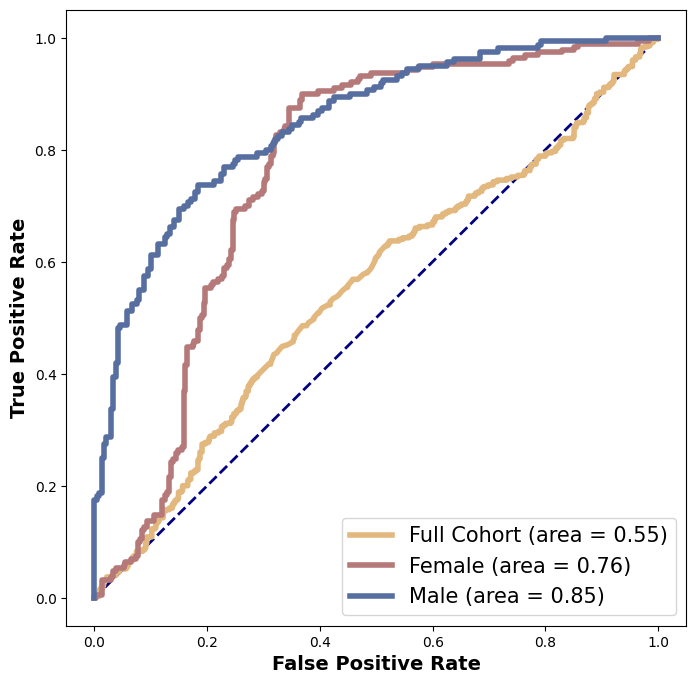

In [26]:
# panel B
models = [
    {'y_true':  y_true_list_lr_all, 'y_pred': y_pred_list_lr_all, 'prob': y_pred_prob_list_lr_all, 'label': 'Full Cohort'},
    {'y_true':  y_true_list_lr_all_F, 'y_pred': y_pred_list_lr_all_F, 'prob': y_pred_prob_list_lr_all_F, 'label': 'Female'},
    {'y_true':  y_true_list_lr_all_M, 'y_pred': y_pred_list_lr_all_M, 'prob': y_pred_prob_list_lr_all_M, 'label': 'Male'},
            ]

plt.figure(figsize=(8, 8))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
# for i, model in enumerate(models):
#     fpr, tpr, _ = roc_curve(model['y_true'], model['prob'])
#     roc_auc = auc(fpr, tpr)
#     plt.plot(fpr, tpr, lw=2, label=f"{model['label']}(area = {roc_auc:.2f})")
colors = ['#e3b87f', '#b57979', '#576fa0']

for model, c in zip(models, colors):
    fpr, tpr, _ = roc_curve(model['y_true'], model['prob'])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=4, color=c, label=f"{model['label']} (area = {roc_auc:.2f})")

plt.xlabel('False Positive Rate', fontsize=14,fontweight='bold')
plt.ylabel('True Positive Rate', fontsize=14,fontweight='bold')
plt.legend(loc='lower right', fontsize=15)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.savefig('../plots/Figure3_PanelB_ROC.pdf', format='pdf', bbox_inches='tight')
plt.show()

In [27]:
combined_evaluation_df = pd.concat([
    # Baseline
    eval_df_baseline_combined,
    eval_df_baseline_male,
    eval_df_baseline_female,
    # Proteomics
    eval_df_proteomics_combined,
    eval_df_proteomics_male,
    eval_df_proteomics_female,
    # Metabolomics
    eval_df_metabolomics_combined,
    eval_df_metabolomics_male,
    eval_df_metabolomics_female,
    # Multi-omics
    eval_df_multiomics_combined,
    eval_df_multiomics_male,
    eval_df_multiomics_female
], ignore_index=True)

In [28]:
combined_evaluation_df

,Model,Groups,Features,AUC,Accuracy,Sensitivity,Specificity
0,LR (Baseline),Full Cohort,Basic,0.441558,0.666667,0.285714,0.909091
1,LR (Baseline),Full Cohort,Basic,0.519481,0.722222,0.428571,0.909091
2,LR (Baseline),Full Cohort,Basic,0.467532,0.555556,0.571429,0.545455
3,LR (Baseline),Full Cohort,Basic,0.512987,0.666667,0.571429,0.727273
4,LR (Baseline),Full Cohort,Basic,0.577922,0.666667,0.571429,0.727273
...,...,...,...,...,...,...,...
595,LR (Overall-Female),Female,Comprehensive,0.708333,0.800000,1.000000,0.666667
596,LR (Overall-Female),Female,Comprehensive,0.500000,0.600000,0.750000,0.500000
597,LR (Overall-Female),Female,Comprehensive,0.958333,0.900000,1.000000,0.833333
598,LR (Overall-Female),Female,Comprehensive,1.000000,1.000000,1.000000,1.000000


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Male_Basic vs. Male_Proteomics: Mann-Whitney-Wilcoxon test two-sided, P_val:4.505e-02 U_stat=1.540e+03
Full Cohort_Basic vs. Full Cohort_Proteomics: Mann-Whitney-Wilcoxon test two-sided, P_val:1.830e-01 U_stat=1.441e+03
Female_Basic vs. Female_Proteomics: Mann-Whitney-Wilcoxon test two-sided, P_val:5.108e-02 U_stat=1.533e+03
Full Cohort_Basic vs. Full Cohort_Metabolomics: Mann-Whitney-Wilcoxon test two-sided, P_val:7.681e-03 U_stat=8.630e+02
Female_Basic vs. Female_Metabolomics: Mann-Whitney-Wilcoxon test two-sided, P_val:4.415e-11 U_stat=2.945e+02
Male_Basic vs. Male_Metabolomics: Mann-Whitney-Wilcoxon test two-sided, P_val:3.667e-10 U_stat=3.430e+02
Male_Basic vs. Male_Comprehensive: Mann-Whitney-Wilcoxon test two-sided, P_val:7.632e-11 U_stat=3.090e+02
Full Cohort_Basic vs. Full Cohort_Comprehe

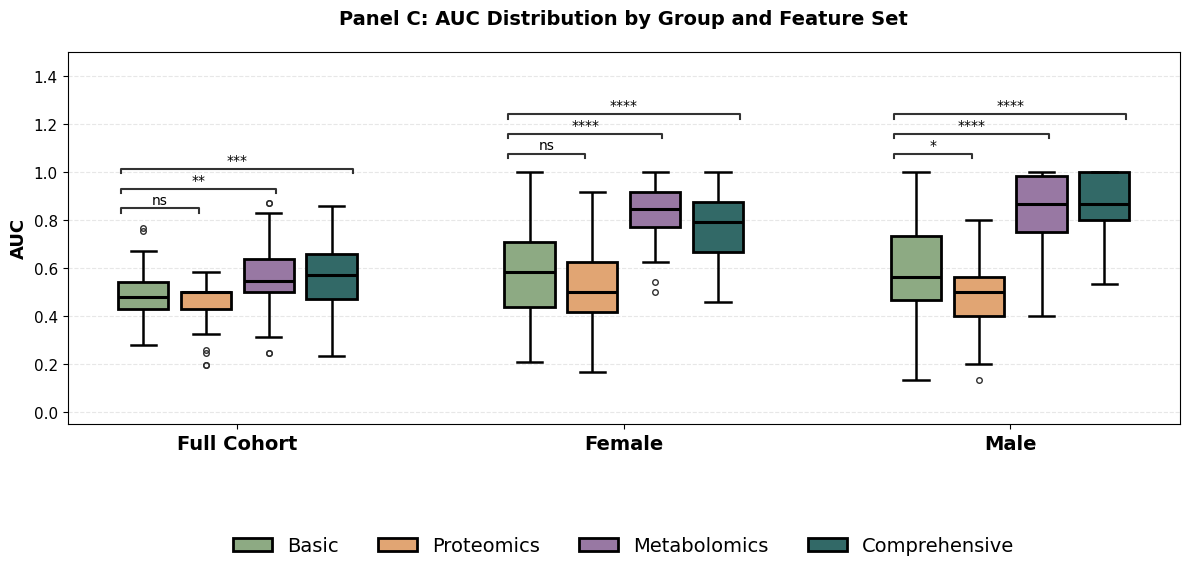

In [29]:
fig = utility.plot_panel_c_boxplot(
    combined_evaluation_df, 
    save_path='../plots/Figure3_PanelC_Boxplot.pdf',
    figsize=(12, 6)
)

In [30]:
feature_selection_df_lr_all_M

,Feature,Total Count
0,Pyrroline hydroxycarboxylic acid,50
1,Neuropsych.MMSE,48
6,epithio-seco-cholestadienetriol S_S-dioxide,44
5,Methylimidazole acetaldehyde,42
4,FA hydroxy(7:0),40
...,...,...
105,APOA4,1
59,2-Isopropyl-3-oxosuccinate,1
108,beta-Alanopine,1
109,Gentisate aldehyde,1


In [31]:
feature_selection_df_lr_all_M['Total Count'].sum() / 50

18.28

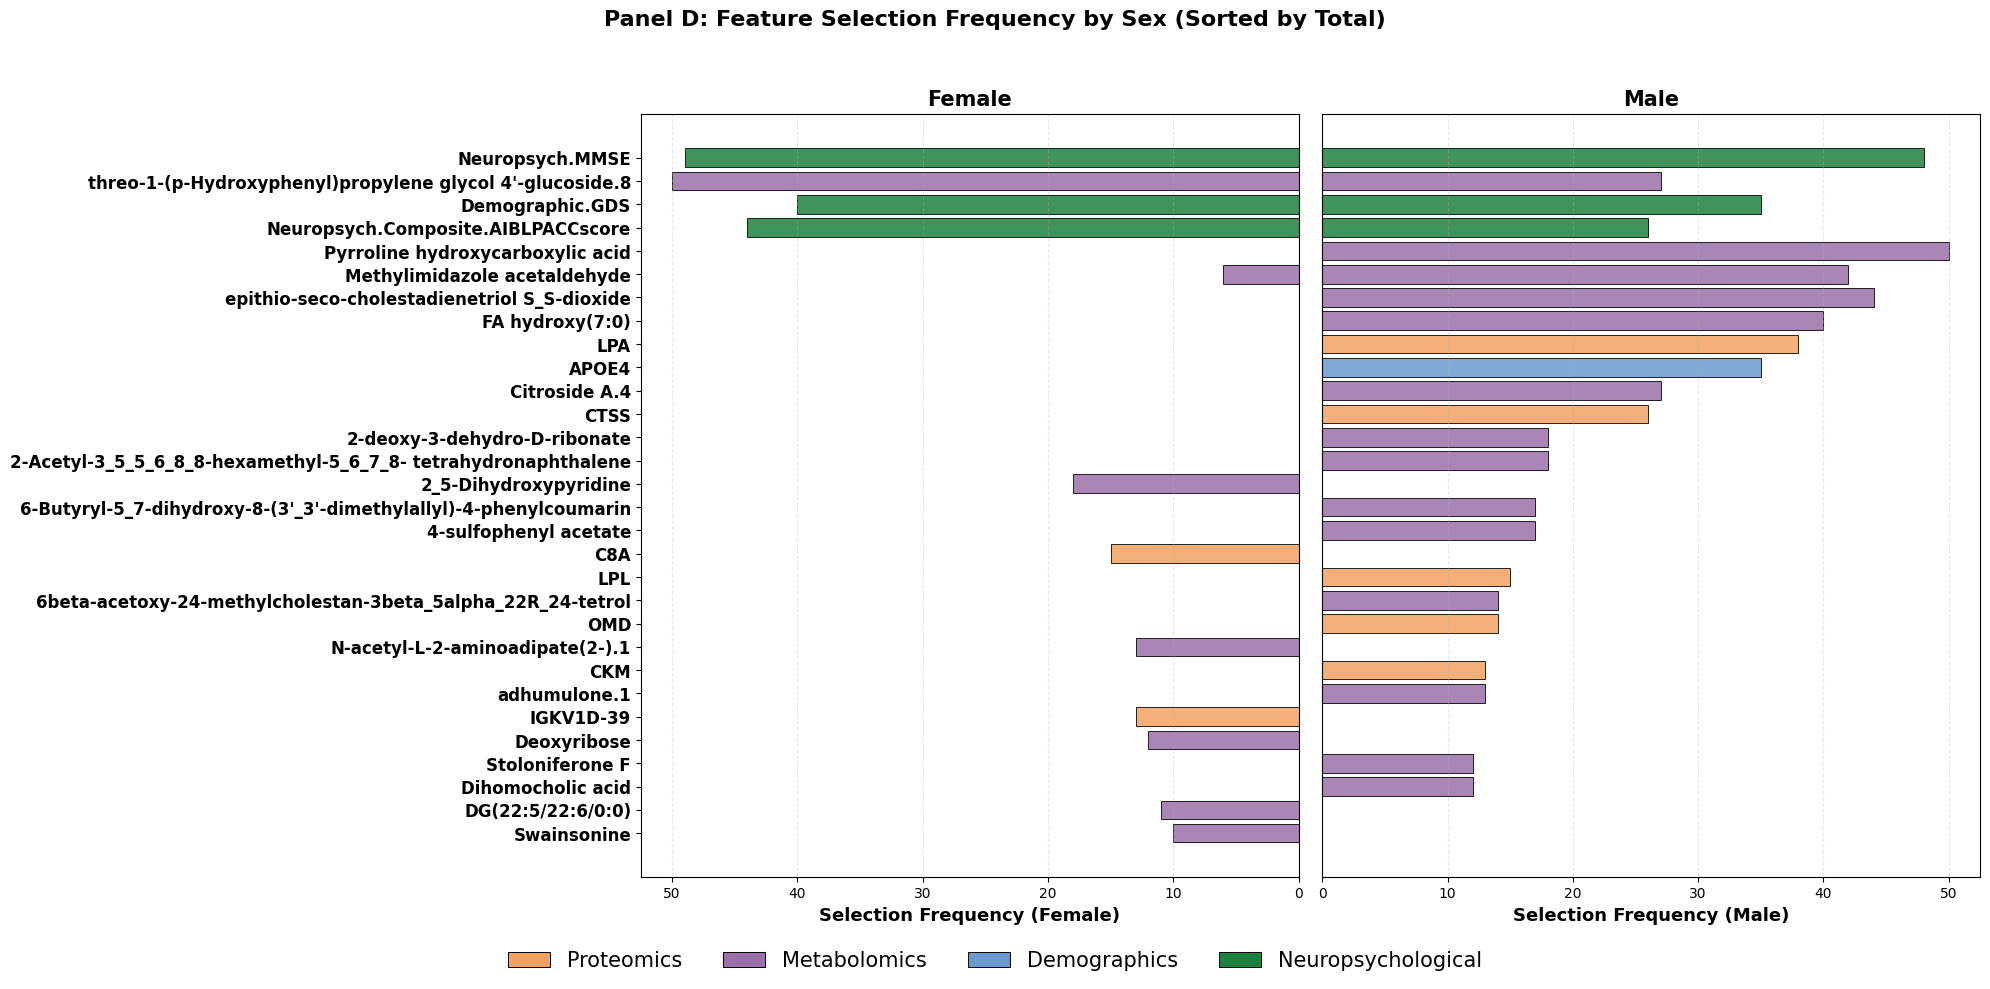

In [32]:
fig = utility.plot_panel_d_butterfly_enhanced(
    feature_selection_df_M=feature_selection_df_lr_all_M,  
    feature_selection_df_F=feature_selection_df_lr_all_F,  
    demographic_cols=demographic_cols,
    proteomic_cols=proteomic_cols,
    metabolomics_cols=metabolomics_cols,
    neuropsychological_cols=neuropsychological_cols,
    top_n=30,
    save_path='../plots/Figure4_PanelA_FeatureSelectionFreq.pdf',
    figsize=(20, 10)
)

Plot saved to ../plots/Figure4_PanelC_FeatureCoefficeint_Male.pdf


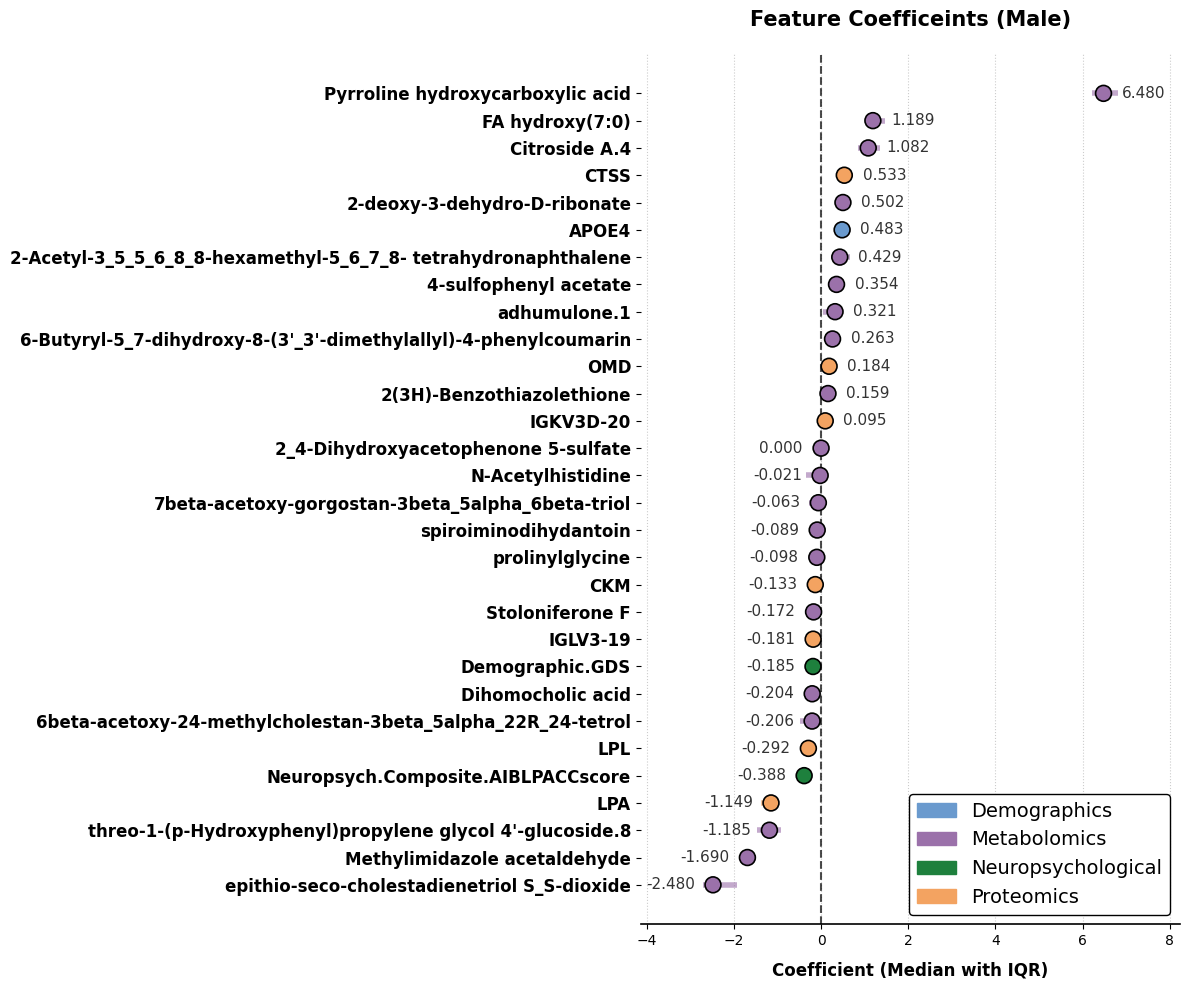

In [33]:
utility.plot_feature_coefficients_lollipop_enhanced(
    feature_sum_coef_df_lr_all_M,
    demographic_cols=demographic_cols,
    proteomic_cols=proteomic_cols,
    metabolomics_cols=metabolomics_cols,
    neuropsychological_cols=neuropsychological_cols,
    top_n=30,
    save_path='../plots/Figure4_PanelC_FeatureCoefficeint_Male.pdf',
    figsize=(12, 10),
    title='Feature Coefficeints (Male)'
)

Plot saved to ../plots/Figure4_PanelB_FeatureCoefficeint_Female.pdf


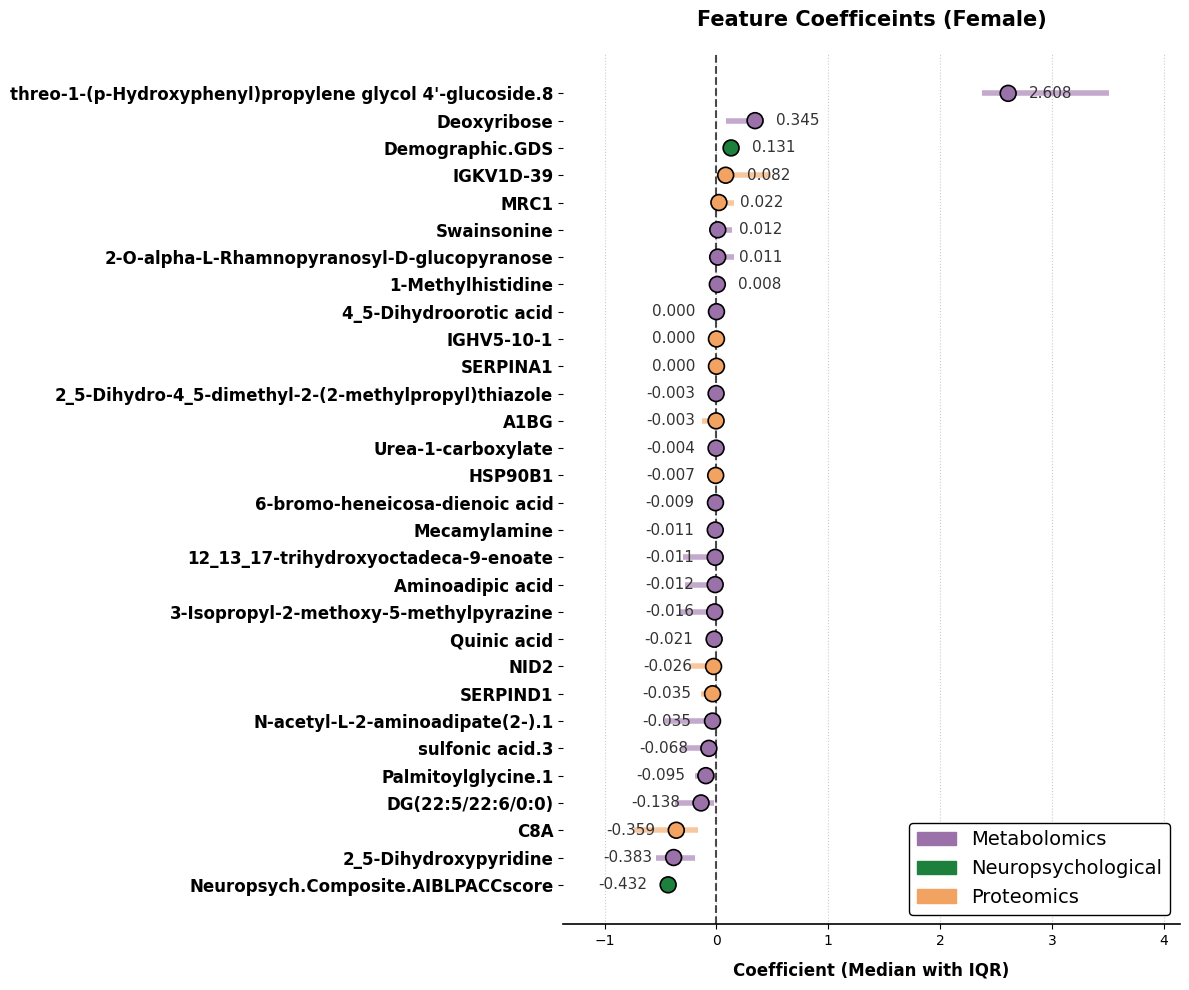

In [34]:
utility.plot_feature_coefficients_lollipop_enhanced(
    feature_sum_coef_df_lr_all_F,
    demographic_cols=demographic_cols,
    proteomic_cols=proteomic_cols,
    metabolomics_cols=metabolomics_cols,
    neuropsychological_cols=neuropsychological_cols,
    top_n=30,
    save_path='../plots/Figure4_PanelB_FeatureCoefficeint_Female.pdf',
    figsize=(12, 10),
    title='Feature Coefficeints (Female)'
)

# Final Panel of Biomarkers

In [35]:
# PLS-DA
plsda_female_full = pd.read_csv('../results/plsda_features_female_vip.csv')
plsda_female_selected = plsda_female_full[plsda_female_full['Selected'] == 'Yes']
selected_features_plsda_F = plsda_female_selected['Feature'].tolist()
print(f"=== PLS-DA (Female) ===")
print(f"Total features: {len(plsda_female_full)}")
print(f"Selected features (VIP > 1): {len(selected_features_plsda_F)}")
# print(f"Mean VIP score: {plsda_female_full['VIP_Score'].mean():.3f}")

plsda_male_full = pd.read_csv('../results/plsda_features_male_vip.csv')
plsda_male_selected = plsda_male_full[plsda_male_full['Selected'] == 'Yes']
selected_features_plsda_M = plsda_male_selected['Feature'].tolist()
print(f"=== PLS-DA (Male) ===")
print(f"Total features: {len(plsda_male_full)}")
print(f"Selected features (VIP > 1): {len(selected_features_plsda_M)}")
# print(f"Mean VIP score: {plsda_male_full['VIP_Score'].mean():.3f}")

=== PLS-DA (Female) ===
Total features: 1941
Selected features (VIP > 1): 629
=== PLS-DA (Male) ===
Total features: 1941
Selected features (VIP > 1): 638


In [36]:
# volcano plot

volcano_female = pd.read_csv('../results/DE_results_Female.csv')
volcano_female_sig = volcano_female[volcano_female['Significance'].isin(['Up', 'Down'])]
selected_features_volcano_F = volcano_female_sig['Feature'].tolist()
print(f"=== Volcano Plot (Female) ===")
print(f"Total significant features: {len(selected_features_volcano_F)}")
print(f"  Up-regulated: {(volcano_female_sig['Significance'] == 'Up').sum()}")
print(f"  Down-regulated: {(volcano_female_sig['Significance'] == 'Down').sum()}")

#####

volcano_male = pd.read_csv('../results/DE_results_Male.csv')
volcano_male_sig = volcano_male[volcano_male['Significance'].isin(['Up', 'Down'])]
selected_features_volcano_M = volcano_male_sig['Feature'].tolist()
print(f"=== Volcano Plot (Male) ===")
print(f"Total significant features: {len(selected_features_volcano_M)}")
print(f"  Up-regulated: {(volcano_male_sig['Significance'] == 'Up').sum()}")
print(f"  Down-regulated: {(volcano_male_sig['Significance'] == 'Down').sum()}")


=== Volcano Plot (Female) ===
Total significant features: 118
  Up-regulated: 48
  Down-regulated: 70
=== Volcano Plot (Male) ===
Total significant features: 72
  Up-regulated: 30
  Down-regulated: 42


In [37]:
# ML models
total_iterations = 50
np.random.seed(42)
# female
avg_features_freq_F = np.ceil(feature_selection_df_lr_all_F['Total Count'].sum() / total_iterations).astype(int)

print(f"Average features per iteration (rounded up): {avg_features_freq_F}")

# Sort by Total_count (frequency) and select top features
selected_features_freq_F = (feature_selection_df_lr_all_F
                     .sort_values('Total Count', ascending=False)
                     .head(avg_features_freq_F)['Feature']
                     .tolist())
selected_features_coef_F = (feature_sum_coef_df_lr_all_F
                             .nlargest(avg_features_freq_F, 'Abs_Mean_Coefficient')
                             .sort_values('Median_Coefficient')
                             ['Feature']  # Assuming your feature column is named 'Feature'
                             .tolist())

# male
avg_features_freq_M = np.ceil(feature_selection_df_lr_all_M['Total Count'].sum() / total_iterations).astype(int)

print(f"Average features per iteration (rounded up): {avg_features_freq_M}")

# Sort by Total_count (frequency) and select top features
selected_features_freq_M = (feature_selection_df_lr_all_M
                     .sort_values('Total Count', ascending=False)
                     .head(avg_features_freq_M)['Feature']
                     .tolist())
selected_features_coef_M = (feature_sum_coef_df_lr_all_M
                             .nlargest(avg_features_freq_M, 'Abs_Mean_Coefficient')
                             .sort_values('Median_Coefficient')
                             ['Feature']  # Assuming your feature column is named 'Feature'
                             .tolist())

Average features per iteration (rounded up): 109
Average features per iteration (rounded up): 19


In [38]:
overlap_F = set(selected_features_freq_F) & set(selected_features_coef_F) & set(selected_features_plsda_F) & set(selected_features_volcano_F)
overlap_M = set(selected_features_freq_M) & set(selected_features_coef_M) & set(selected_features_plsda_M) & set(selected_features_volcano_M)

In [39]:
print(len(overlap_F))
print(len(overlap_M))

36
12


In [40]:
overlap_M

{"6-Butyryl-5_7-dihydroxy-8-(3'_3'-dimethylallyl)-4-phenylcoumarin",
 '6beta-acetoxy-24-methylcholestan-3beta_5alpha_22R_24-tetrol',
 'CTSS',
 'Citroside A.4',
 'FA hydroxy(7:0)',
 'LPA',
 'LPL',
 'Methylimidazole acetaldehyde',
 'OMD',
 'Pyrroline hydroxycarboxylic acid',
 'epithio-seco-cholestadienetriol S_S-dioxide',
 "threo-1-(p-Hydroxyphenyl)propylene glycol 4'-glucoside.8"}

In [41]:
overlap_F

{'(S)C(S)S-S-Methylcysteine sulfoxide',
 '1-deoxyxylonojirimycin',
 '2-Aminoacrylic acid',
 '2-O-alpha-L-Rhamnopyranosyl-D-glucopyranose',
 '2_3-Dihydroxycyclopentaneundecanoic acid',
 '2_5-Dihydroxypyridine',
 '3-Isopropyl-2-methoxy-5-methylpyrazine',
 '5-dehydro-4-deoxy-2-O-sulfo-D-glucuronate',
 '6-bromo-heneicosa-dienoic acid',
 'Aminoadipic acid',
 'C8A',
 'Citroside A.3',
 'D-desosamine.1',
 'DG(22:5/22:6/0:0)',
 'Dehydroascorbic acid.1',
 'Ethyl -3-hydroxybutyrate',
 'HSP90B1',
 'IGKV1D-39',
 'ITGB3',
 'MRC1',
 'Mannosamine',
 'Mecambrine',
 'Mecamylamine',
 'Methylimidazole acetaldehyde',
 'N(6)-Methyllysine',
 'N-acetyl-L-2-aminoadipate(2-).1',
 'NID2',
 'Octaethylene glycol',
 'PON1',
 'Quinic acid',
 'SERPINA1',
 'SERPIND1',
 'Swainsonine',
 'Thallium',
 'sulfonic acid.3',
 "threo-1-(p-Hydroxyphenyl)propylene glycol 4'-glucoside.8"}

In [49]:
pd.DataFrame({'Female': pd.Series(list(overlap_F)), 'Male': pd.Series(list(overlap_M))}).apply(lambda s: s.sort_values(ignore_index=True)).to_excel('../results/final_features_overlap.xlsx', index=False)


In [42]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score,accuracy_score,f1_score,precision_score

In [45]:
# Female
X_F=model_all_df_F[list(overlap_F)]
y_F=model_all_df_F['label']
Xtr_F,Xte_F,ytr_F,yte_F=train_test_split(X_F,y_F,test_size=0.2,random_state=42,stratify=y_F)
m_F=LogisticRegression(max_iter=1000,solver="liblinear").fit(Xtr_F,ytr_F)
p=m_F.predict(Xte_F); s=m_F.predict_proba(Xte_F)[:,1]

metrics=pd.DataFrame([{"AUC":roc_auc_score(yte_F,s),"Accuracy":accuracy_score(yte_F,p),"F1":f1_score(yte_F,p),"Precision":precision_score(yte_F,p)}])
print(f"AUC={roc_auc_score(yte_F,s):.3f}, Accuracy={accuracy_score(yte_F,p):.3f}, F1={f1_score(yte_F,p):.3f}")


X_F=model_all_df_F[list(overlap_F)]
y_F=model_all_df_F['label']
m_F=LogisticRegression(max_iter=1000,solver="liblinear").fit(X_F,y_F)
coefs_F=pd.DataFrame({"feature":list(overlap_F),"coefficient":m_F.coef_[0]})
coefs_F = pd.concat([coefs_F, pd.DataFrame({"feature":["Intercept"], "coefficient":[m_F.intercept_[0]]})], ignore_index=True)
coefs_F.to_csv("../results/logistic_feature_coefficients_Female.csv",index=False)
df_F = model_all_df_F[list(overlap_F)+['label']]
df_F.to_csv("../results/final_omics_Female.csv",index=False)

AUC=1.000, Accuracy=0.800, F1=0.667


In [46]:
# Male
X_M=model_all_df_M[list(overlap_M)]
y_M=model_all_df_M['label']
Xtr_M,Xte_M,ytr_M,yte_M=train_test_split(X_M,y_M,test_size=0.2,random_state=42,stratify=y_M)
m_M=LogisticRegression(max_iter=1000,solver="liblinear").fit(Xtr_M,ytr_M)
p=m_M.predict(Xte_M); s=m_M.predict_proba(Xte_M)[:,1]
metrics=pd.DataFrame([{"AUC":roc_auc_score(yte_M,s),"Accuracy":accuracy_score(yte_M,p),"F1":f1_score(yte_M,p),"Precision":precision_score(yte_M,p)}])
print(f"AUC={roc_auc_score(yte_M,s):.3f}, Accuracy={accuracy_score(yte_M,p):.3f}, F1={f1_score(yte_M,p):.3f}")


X_M=model_all_df_M[list(overlap_M)]
y_M=model_all_df_M['label']
m_M=LogisticRegression(max_iter=1000,solver="liblinear").fit(X_M,y_M)
coefs_M=pd.DataFrame({"feature":list(overlap_M),"coefficient":m_M.coef_[0]})
coefs_M = pd.concat([coefs_M, pd.DataFrame({"feature":["Intercept"], "coefficient":[m_M.intercept_[0]]})], ignore_index=True)
coefs_M.to_csv("../results/logistic_feature_coefficients_Male.csv",index=False)
df_M = model_all_df_M[list(overlap_M)+['label']]
df_M.to_csv("../results/final_omics_Male.csv",index=False)

AUC=1.000, Accuracy=0.875, F1=0.800
